In [9]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

In [10]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\eda_house_price_dataset.csv")

In [11]:
df.shape

(10300, 6)

In [12]:
df.columns

Index(['Size (sq. ft.)', 'Bedrooms', 'Bathrooms', 'Age of House (Years)',
       'Distance to City Center (Miles)', 'Price'],
      dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 6 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Size (sq. ft.)                   9993 non-null   float64
 1   Bedrooms                         9986 non-null   float64
 2   Bathrooms                        9987 non-null   float64
 3   Age of House (Years)             9989 non-null   float64
 4   Distance to City Center (Miles)  9992 non-null   float64
 5   Price                            9991 non-null   float64
dtypes: float64(6)
memory usage: 482.9 KB


In [14]:
df.describe()

,Size (sq. ft.),Bedrooms,Bathrooms,Age of House (Years),Distance to City Center (Miles),Price
count,9993.000000,9986.000000,9987.000000,9989.000000,9992.000000,9991.000000
mean,2773.847581,2.977068,2.494543,25.016018,10.006183,65696.135388
std,1264.406685,1.409452,1.130059,14.690538,5.725877,140815.631584
min,600.051193,1.000000,1.000000,0.000000,0.102037,-365834.936400
25%,1684.168946,2.000000,1.000000,12.000000,5.136444,-37625.375810
50%,2765.311690,3.000000,3.000000,25.000000,9.983691,67385.925300
75%,3849.176521,4.000000,4.000000,38.000000,14.931337,168142.915100
max,4998.757762,5.000000,4.000000,50.000000,19.998004,447373.485600


In [15]:
df.dtypes

Size (sq. ft.)                     float64
Bedrooms                           float64
Bathrooms                          float64
Age of House (Years)               float64
Distance to City Center (Miles)    float64
Price                              float64
dtype: object

In [16]:
df.isna().sum()

Size (sq. ft.)                     307
Bedrooms                           314
Bathrooms                          313
Age of House (Years)               311
Distance to City Center (Miles)    308
Price                              309
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(300)

In [19]:
df["Size (sq. ft.)"] = df["Size (sq. ft.)"].fillna(df["Size (sq. ft.)"].mean())
df["Bedrooms"] = df["Bedrooms"].fillna(df["Bedrooms"].mean())
df["Age of House (Years)"] = df["Age of House (Years)"].fillna(df["Age of House (Years)"].mean())
df["Distance to City Center (Miles)"] = df["Distance to City Center (Miles)"].fillna(df["Distance to City Center (Miles)"].mean())
df["Price"] = df["Price"].fillna(df["Price"].mean())

In [20]:
df.isna().sum()

Size (sq. ft.)                       0
Bedrooms                             0
Bathrooms                          313
Age of House (Years)                 0
Distance to City Center (Miles)      0
Price                                0
dtype: int64

In [21]:
df["Bathrooms"]=df["Bathrooms"].fillna(df["Bathrooms"].mean())

In [22]:
df.isna().sum()

Size (sq. ft.)                     0
Bedrooms                           0
Bathrooms                          0
Age of House (Years)               0
Distance to City Center (Miles)    0
Price                              0
dtype: int64

In [23]:
df["Price"]=df["Price"].apply(lambda x:x*(-1) if x<0 else x*(1))

In [24]:
df

,Size (sq. ft.),Bedrooms,Bathrooms,Age of House (Years),Distance to City Center (Miles),Price
0,1543.388525,5.0,2.000000,21.0,5.363322,138900.290300
1,2546.092744,3.0,3.000000,12.0,8.940724,86109.931030
2,2480.852724,5.0,1.000000,18.0,3.543647,264942.561400
3,1343.314278,5.0,2.494543,41.0,17.081160,110053.768500
4,4894.488693,2.0,4.000000,6.0,16.646904,55148.743140
...,...,...,...,...,...,...
10295,4453.885567,1.0,2.494543,16.0,9.778924,47703.013640
10296,2773.847581,4.0,1.000000,45.0,5.021931,113370.801600
10297,4527.755529,4.0,1.000000,20.0,3.130250,341658.764900
10298,3967.391718,4.0,1.000000,37.0,16.872878,772.812653


In [25]:
model = LinearRegression()

In [26]:
x = df[["Size (sq. ft.)","Bedrooms","Bathrooms","Age of House (Years)","Distance to City Center (Miles)"]]

In [27]:
y = df["Price"]

In [28]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=4444)

In [31]:
x_train.isna().sum()

Size (sq. ft.)                     0
Bedrooms                           0
Bathrooms                          0
Age of House (Years)               0
Distance to City Center (Miles)    0
dtype: int64

In [33]:
y_train

5598    249247.206700
6063    264977.990900
4861     23523.477630
1706     65696.135388
34        4960.404520
            ...      
5205    194337.191800
4275    158192.502200
8091     63706.881640
7471     28619.914750
8361    221580.961400
Name: Price, Length: 8240, dtype: float64

In [34]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [35]:
y_predict = model.predict(x_test)

In [36]:
y_predict

array([133568.37751601, 123324.62717668,  95994.55733849, ...,
        83671.24284507, 115094.20945429,  46074.90333416], shape=(2060,))

In [38]:
mae = mean_absolute_error(y_predict,y_test)

In [39]:
mae

59861.34862186858

In [40]:
mse = mean_squared_error(y_predict,y_test)

In [41]:
mse

5431641780.848007

In [42]:
rmse = root_mean_squared_error(y_predict,y_test)

In [43]:
rmse

73699.67286798502

In [44]:
r2 = r2_score(y_predict,y_test)

In [45]:
r2

-1.3714781977853665

In [47]:
# df.columns
a = int(input("enter the size"))
b = int(input("enter the bed"))
c = int(input("enter the bath"))
d = int(input("enter the distans"))
e = int(input("enter milles"))
y_predict = model.predict([[a,b,c,d,e]])

enter the size 10
enter the bed 20
enter the bath 30
enter the distans 40
enter milles 60


C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [48]:
y_predict

array([12805.16475731])

In [50]:

import pandas as pd

# Import libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Load dataset
df = pd.read_csv(r"C:\Users\Admin\Downloads\eda_house_price_dataset.csv")

# Remove rows with missing target values
df = df.dropna(subset=["Price"])

# Remove invalid negative house prices
df = df[df["Price"] > 0]

# Independent and dependent variables
X = df.drop("Price", axis=1)
y = df["Price"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create preprocessing and model pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# Train model
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

# Evaluation
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)


R2 Score: 0.9185268206584177
MAE: 19417.317305584234
MSE: 746805519.8689357
RMSE: 27327.742677889364


In [51]:
import matplotlib.pyplot as plt

ValueError: x and y must be the same size

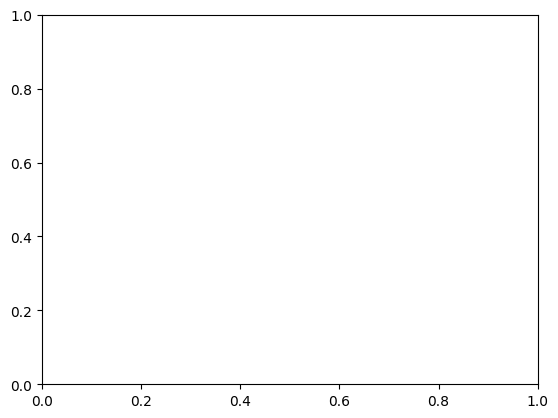

In [53]:
plt.scatter(x_train,y_train)